In [1]:
from bs4 import BeautifulSoup
import requests
url="https://traveltriangle.com/tour-packages/india"
headers={
    "user-agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/146.0.0.0 Safari/537.36"
}
response=requests.get(url,headers=headers)
response

<Response [200]>

In [2]:
response.status_code

200

In [3]:
html_code=response.text

In [4]:
html_code[:1000]

'<!doctype html><html lang="en" data-reactroot=""><head><link href="https://assets.traveltriangle.com" rel="dns-prefetch"/><link href="https://fonts.gstatic.com" rel="dns-prefetch"/><link href="https://www.googletagmanager.com" rel="dns-prefetch"/><link href="https://connect.facebook.net" rel="dns-prefetch"/><link href="https://www.google-analytics.com" rel="dns-prefetch"/><link href="//www.googleadservices.com" rel="dns-prefetch"/><link rel="preload" href="https://fonts.gstatic.com/s/lato/v13/qIIYRU-oROkIk8vfvxw6QvesZW2xOQ-xsNqO47m55DA.woff" as="font" type="font/woff2" crossorigin="anonymous"/><link rel="preload" as="script" href="https://assets.traveltriangle.com/desktop_assets/build/runtime-b6b31397af368af98f7c.js" charSet="UTF-8"/><link rel="preload" as="script" href="https://assets.traveltriangle.com/desktop_assets/build/vendor-react-03b39ad1fcca23b5a27e.js" charSet="UTF-8"/><link rel="preload" as="script" href="https://assets.traveltriangle.com/desktop_assets/build/vendor-chunks-

In [5]:
soup=BeautifulSoup(html_code)

In [6]:
soup.text

'3 India Tour Packages - Book India Holiday Packages at Best Prices @ TT1800-123-5555Travel Agent? Join UsBlogOffersDownload AppGet Travel Triangle in your pocket.Get your app via smsGet AppLoginHoneymoon PackagesFamily PackagesHoliday PackagesHoliday DealsLuxury HolidaysHotelsDestination GuidesHoliday ThemesPlan My HolidayIndian DestinationsKashmirHimachalGoaRajasthanKeralaAndamanSikkimUttarakhandView AllInternational DestinationsBaliSri LankaMaldivesVietnamMauritiusEuropeDubaiThailandSingaporeTurkeyBhutanSeychellesView AllIndian DestinationsKeralaHimachalRajasthanGoaKashmirAndamanSikkimGujaratView AllInternational DestinationsDubaiSingaporeEuropeBhutanMauritiusVietnamSri LankaBaliThailandTurkeyMaldivesAustraliaView AllIndian DestinationsKeralaAndamanHimachalSikkimKashmirRajasthanGoaUttarakhandView AllInternational DestinationsBaliMaldivesSri LankaEuropeMalaysiaTurkeyThailandMauritiusDubaiSingaporeSwitzerlandSeychellesView AllIndian DestinationsKeralaHimachalAndamanKashmirInternationa

In [7]:
title=soup.find("span",attrs = {"class":"fw9 m0 f16 pfc3"})
title.text

'Most Reasonable Goa Honeymoon Tour Packages'

In [8]:
price=soup.find("p",attrs = {"class":"sfc3 m0 f20 fw9 priceVal at_newprice"})
price.text

'â\x82¹ 7,999/-â\x82¹ 9,142/-'

In [9]:
discount=soup.find("span",attrs = {"class":"f12 fw4 pt2 pb2 pl8 pr8 radius20 pbc1 sfcw at_discount_label"})
discount.text

'13% Off'

In [10]:
city=soup.find("ul",attrs = {"class":"clearfix package-cities-list at_packagecity_list"})
city.text

'Goa (5D)'

In [11]:
hotels=soup.find("div",attrs = {"class":"flex alignCenter"})
hotels.text

'3 Star2 Star4 Star'

In [12]:
category=soup.find("div",attrs = {"class":"col-md-5 pl8 pr0 clearfix package-tag-box"})
category.text

'Hot PickWater ActivitiesRomantic CruiseAdventureCandlelight dinnerCruisesNatureBeach hoppingRomanticBudget'

In [13]:
sharing=soup.find("p",attrs = {"class":"f12 m0 pfc4 fw7 at_sharinginfo"})
sharing.text


'Per Person on twin sharing'

In [14]:
old_price=soup.find("span",attrs = {"class":"f12 pfc3 tdl ml8 at_oldprice fw4"})
old_price.text


'â\x82¹ 9,142/-'

In [ ]:
import numpy as np
title_data=[]
price_data=[]
duration_data=[]
discount_data=[]
city_data=[]
hotel_data=[]
category_data=[]
sharing_data=[]
package_data=[]
for i in range(1,197):
    url=f"https://traveltriangle.com/tour-packages/india/page/{i}"
    headers={
        "user-agent":"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/146.0.0.0 Safari/537.36 Edg/146.0.0.0"

    }
    response=requests.get(url,headers=headers)

    html_code=response.text
    soup=BeautifulSoup(html_code)
    container=soup.find_all("div",attrs={"class":"packageCardWidth"})

    for c in container:
        title=c.find("span",attrs = {"class":"fw9 m0 f16 pfc3"})
        if title is None:
            title_data.append(np.nan)
        else:
            title_data.append(title.text)

        price=c.find("p",attrs = {"class":"sfc3 m0 f20 fw9 priceVal at_newprice"})
        if price is None:
            price_data.append(np.nan)
        else:
            price_data.append(price.text)

        duration=c.find("span",attrs = {"class":"f12 m0 iblock fw7 at_package_duration"})
        if duration is None:
            duration_data.append(np.nan)
        else:
            duration_data.append(duration.text)

        discount=c.find("span",attrs = {"class":"f12 fw4 pt2 pb2 pl8 pr8 radius20 pbc1 sfcw at_discount_label"})
        if discount is None:
            discount_data.append(np.nan)
        else:
            discount_data.append(discount.text)

        city=c.find("ul",attrs = {"class":"clearfix package-cities-list at_packagecity_list"})
        if city is None:
            city_data.append(np.nan)
        else:
            city_data.append(city.text)

        hotel=c.find("div",attrs = {"class":"flex alignCenter"})
        if hotel is None:
            hotel_data.append(np.nan)
        else:
            hotel_data.append(hotel.text)

        category=c.find("div",attrs = {"class":"col-md-5 pl8 pr0 clearfix package-tag-box"})
        if category is None:
            category_data.append(np.nan)
        else:
            category_data.append(category.text)

        sharing=c.find("p",attrs = {"class":"f12 m0 pfc4 fw7 at_sharinginfo"})
        if sharing is None:
            sharing_data.append(np.nan)
        else:
            sharing_data.append(sharing.text)

        package=c.find("div",attrs = {"class":"col-12 p8 flex absolute t142 wfull"})
        if package is None:
            package_data.append(np.nan)
        else:
            package_data.append(package.text)


In [ ]:
print("Title Data:",len(title_data))
print("Title Data:",len(price_data))
print("Rating Data:",len(duration_data))
print("Price Data:",len(discount_data))
print("Review Data:",len(category_data))
print("Feature Data:",len(hotel_data))
print("Title Data:",len(city_data))
print("Rating Data:",len(sharing_data))
print("Price Data:",len(package_data))

In [ ]:
print(container[0].find("span",attrs = {"class":"fw9 m0 f16 pfc3"}).text)
print(container[0].find("p",attrs = {"class":"sfc3 m0 f20 fw9 priceVal at_newprice"}).text)
print(container[0].find("span",attrs = {"class":"f12 m0 iblock fw7 at_package_duration"}).text)
print(container[0].find("span",attrs = {"class":"f12 fw4 pt2 pb2 pl8 pr8 radius20 pbc1 sfcw at_discount_label"}).text)
print(container[0].find("ul",attrs = {"class":"clearfix package-cities-list at_packagecity_list"}).text)
print(container[0].find("div",attrs = {"class":"flex alignCenter"}).text)

print(container[0].find("div",attrs = {"class":"col-md-5 pl8 pr0 clearfix package-tag-box"}).text)
print(container[0].find("p",attrs = {"class":"f12 m0 pfc4 fw7 at_sharinginfo"}).text)
print(container[0].find("div",attrs = {"class":"col-12 p8 flex absolute t142 wfull"}).text)

In [ ]:
import pandas as pd
df=pd.DataFrame(
    {
        "Title":title_data,
        "Price":price_data,
        "Duration":duration_data,
        "Discount":discount_data,
        "City":city_data,
        "Hotels":hotel_data,
        "Dinner_category":category_data,
        "Package_sharing":sharing_data,
        "included_services":package_data
    }
)
print(len(df))
df.to_csv("Tour_Package.csv", index=False)

In [120]:
import pandas as pd
import numpy as np
import re
df=pd.read_csv("Tour_Packages.csv")
len(df)

3920

In [124]:
df.head(10)

,Title,Price,Duration,Discount,City,Hotels,Dinner_category,Package_sharing,included_services
0,Most Reasonable Goa Honeymoon Tour PackagesPle...,"â¹ 7,999/-â¹ 9,142/-",5 Days & 4 Nights,13% Off,Goa (5D),3 Star2 Star4 Star,Hot PickWater ActivitiesRomantic CruiseAdventu...,Per Person on twin sharing,Upto 2 StarsMealsSightseeing+2 moreAirport Pic...
1,Fantastic Andaman Honeymoon PackagePlease dese...,"â¹ 15,599/-â¹ 18,811/-",5 Days & 4 Nights,17% Off,Port Blair (3D)Havelock (2D),3 Star,Corbyn's Beach CoveAdventureRadhanagar BeachNa...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreTransfersWa...
2,Romantic Mussoorie Tour Package From DelhiPlea...,"â¹ 10,500/-â¹ 12,000/-",3 Days & 2 Nights,13% Off,Mussoorie (3D),3 Star2 Star4 Star,SightseeingNatureHill stationHimalayasRomantic...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+1 moreTransfers
3,Coorg Package For 2 Nights And 3 DaysPlease de...,"â¹ 14,500/-â¹ 15,934/-",3 Days & 2 Nights,9% Off,Coorg (3D),3 Star,Coorg sightseeingAdventureRajaâs SeatNatureA...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...
4,Best 4N 5D Andaman Sightseeing Tour Package Fo...,"â¹ 33,200/-â¹ 36,484/-",5 Days & 4 Nights,9% Off,Port Blair (4D)Havelock (1D),3 Star,Cellular JailLight & Sound ShowAdventureNature...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...
5,Mesmerising Manali Trip Package From Chandigar...,"â¹ 9,500/-â¹ 10,440/-",3 Days & 2 Nights,9% Off,Manali (3D),3 Star,Hadimba TempleAdventureSolang ValleyNatureRoht...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...
6,Hills & Houseboat: Munnar and Alleppey Honeymo...,"â¹ 22,000/-â¹ 24,444/-",6 Days & 5 Nights,10% Off,Munnar (2D)Thekkady (1D)Alleppey (1D)Kochi (2D),3 Star4 Star5 Star,Periyar Wildlife SanctuaryCruisesEravikulam N...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreTransfersHo...
7,Top Family Holiday Packages in Goa for an Idea...,"â¹ 9,999/-â¹ 10,868/-",5 Days & 4 Nights,8% Off,Calangute (5D),3 Star,FamilyDolphin spottingCruisesKid's SpecialBest...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 morePrivate Cab...
8,Most Affordable 1 Night 2 Days Uttarakhand Tou...,"â¹ 2,800/-â¹ 3,360/-",2 Days & 1 Nights,17% Off,Rishikesh (2D),3 Star2 Star4 Star,River RaftingHill stationAdventureNatureTrekki...,Per Person on twin sharing,Upto 2 StarsMealsSightseeing+2 moreStay Includ...
9,Top 4 Nights 5 Days Best-Selling Sikkim Gangto...,"â¹ 22,000/-â¹ 26,258/-",5 Days & 4 Nights,16% Off,Gangtok (2D)Darjeeling (3D),3 Star4 Star,Best-SellingHimalayaHill stationRoad TripSight...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreAirport Pic...


In [125]:
df.tail()

,Title,Price,Duration,Discount,City,Hotels,Dinner_category,Package_sharing,included_services
3915,5-Day Kerala Tour with Munnar and Houseboat Ad...,"â¹ 27,104/-â¹ 30,800/-",5 Days & 4 Nights,12% Off,Munnar (2D)Thekkady (1D)Alleppey (1D),3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreGST/VAT/ Se...
3916,2-Day Nature Retreat in Kerala's VagamonPlease...,"â¹ 7,990/-â¹ 9,400/-",2 Days & 1 Nights,15% Off,Vagamon (1D),3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+3 moreGST/VAT/ Se...
3917,"Explore Kerala: 5-Day Scenic Tour of Munnar, T...","â¹ 26,690/-â¹ 31,400/-",5 Days & 4 Nights,15% Off,Munnar (2D)Thekkady (1D)Alleppey (1D),3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+3 moreGST/VAT/ Se...
3918,6-Day Kerala Tour: Cherai to AlleppeyPlease de...,"â¹ 31,740/-â¹ 34,500/-",6 Days & 5 Nights,8% Off,Cherai (1D)Munnar (2D)Thekkady (1D)Alleppey (1...,3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreCab Transfe...
3919,"7-Day Kerala Tour with Munnar, Thekkady, and A...","â¹ 41,833/-â¹ 45,970/-",7 Days & 6 Nights,9% Off,Munnar (2D)Thekkady (1D)Alleppey (1D)Kovalam (...,3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+3 moreGST/VAT/ Se...


In [126]:
df.describe()

,Title,Price,Duration,Discount,City,Hotels,Dinner_category,Package_sharing,included_services
count,3882,3882,3920,3917,3907,3804,3882,3920,3882
unique,3246,2070,15,31,1235,29,2499,2,300
top,"5-Day Kerala Tour with Munnar, Thekkady, and A...","â¹ 20,000/-â¹ 21,739/-",4 Days & 3 Nights,9% Off,Munnar (2D)Thekkady (1D)Alleppey (1D)Cochin (1D),3 Star,Quote Package,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...
freq,12,33,834,1365,104,2309,701,3909,1242


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3920 entries, 0 to 3919
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Title              3882 non-null   object
 1   Price              3882 non-null   object
 2   Duration           3920 non-null   object
 3   Discount           3917 non-null   object
 4   City               3907 non-null   object
 5   Hotels             3804 non-null   object
 6   Dinner_category    3882 non-null   object
 7   Package_sharing    3920 non-null   object
 8   included_services  3882 non-null   object
dtypes: object(9)
memory usage: 275.8+ KB


In [128]:
df.shape

(3920, 9)

In [129]:
df.isnull().sum()

Title                 38
Price                 38
Duration               0
Discount               3
City                  13
Hotels               116
Dinner_category       38
Package_sharing        0
included_services     38
dtype: int64

<head>
<title></title>
</head>
<body>
    <h1>Regular Expression</h1>
</body>

In [130]:
df["Price"].isnull().sum()

np.int64(38)

In [131]:
df["Price_₹"] = df["Price"].astype(str).str.extract(r'(\d{1,3}(?:,\d{3})+)')[0]
df["Price_₹"] = df["Price_₹"].str.replace(',', '').astype('Int64')

In [132]:
df["old_Price_₹"] = df["Price"].astype(str).str.findall(r'\d{1,3}(?:,\d{3})+')
df["old_Price_₹"] = df["old_Price_₹"].apply(lambda x: x[1] if len(x) > 1 else None)
df["old_Price_₹"] = df["old_Price_₹"].str.replace(',', '', regex=False).astype('Int64')

In [133]:
df['Days'] = df['Duration'].str.extract(r'(\d+)\s*Days').astype(int)
df['Nights'] = df['Duration'].str.extract(r'(\d+)\s*Nights').astype(int)

In [134]:
df['Discount'] = df['Discount'].str.extract(r'(\d+)').astype(float)

In [135]:
regex=r'\b([A-Za-z\s]+)\s*\(\d+D\)'
df["Cities"]=df["City"].astype(str).apply(lambda x:re.findall(regex,x)[0]if re.findall(regex,x) else None)
df.head()

,Title,Price,Duration,Discount,City,Hotels,Dinner_category,Package_sharing,included_services,Price_₹,old_Price_₹,Days,Nights,Cities
0,Most Reasonable Goa Honeymoon Tour PackagesPle...,"â¹ 7,999/-â¹ 9,142/-",5 Days & 4 Nights,13.0,Goa (5D),3 Star2 Star4 Star,Hot PickWater ActivitiesRomantic CruiseAdventu...,Per Person on twin sharing,Upto 2 StarsMealsSightseeing+2 moreAirport Pic...,7999,9142,5,4,Goa
1,Fantastic Andaman Honeymoon PackagePlease dese...,"â¹ 15,599/-â¹ 18,811/-",5 Days & 4 Nights,17.0,Port Blair (3D)Havelock (2D),3 Star,Corbyn's Beach CoveAdventureRadhanagar BeachNa...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreTransfersWa...,15599,18811,5,4,Port Blair
2,Romantic Mussoorie Tour Package From DelhiPlea...,"â¹ 10,500/-â¹ 12,000/-",3 Days & 2 Nights,13.0,Mussoorie (3D),3 Star2 Star4 Star,SightseeingNatureHill stationHimalayasRomantic...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+1 moreTransfers,10500,12000,3,2,Mussoorie
3,Coorg Package For 2 Nights And 3 DaysPlease de...,"â¹ 14,500/-â¹ 15,934/-",3 Days & 2 Nights,9.0,Coorg (3D),3 Star,Coorg sightseeingAdventureRajaâs SeatNatureA...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...,14500,15934,3,2,Coorg
4,Best 4N 5D Andaman Sightseeing Tour Package Fo...,"â¹ 33,200/-â¹ 36,484/-",5 Days & 4 Nights,9.0,Port Blair (4D)Havelock (1D),3 Star,Cellular JailLight & Sound ShowAdventureNature...,Per Person on twin sharing,Upto 3 StarsMealsSightseeing+2 moreStay Includ...,33200,36484,5,4,Port Blair


In [136]:
regex=r'\d+\s*Star?'
df["Hotels"]=df["included_services"].astype(str).apply(lambda x:re.findall(regex,x)[0]if re.findall(regex,x) else None)


<head>
<title></title>
</head>
<body>
    <h1>EDA</h1>
    <h2>Missing Values<h2>
</body>

In [137]:
df.drop(["Duration","Dinner_category","included_services","Price","City"],axis=1,inplace=True)

In [141]:
df

,Title,Discount,Hotels,Package_sharing,Price_₹,old_Price_₹,Days,Nights,Cities
0,Most Reasonable Goa Honeymoon Tour PackagesPle...,13.0,2 Star,Per Person on twin sharing,7999,9142,5,4,Goa
1,Fantastic Andaman Honeymoon PackagePlease dese...,17.0,3 Star,Per Person on twin sharing,15599,18811,5,4,Port Blair
2,Romantic Mussoorie Tour Package From DelhiPlea...,13.0,3 Star,Per Person on twin sharing,10500,12000,3,2,Mussoorie
3,Coorg Package For 2 Nights And 3 DaysPlease de...,9.0,3 Star,Per Person on twin sharing,14500,15934,3,2,Coorg
4,Best 4N 5D Andaman Sightseeing Tour Package Fo...,9.0,3 Star,Per Person on twin sharing,33200,36484,5,4,Port Blair
...,...,...,...,...,...,...,...,...,...
3915,5-Day Kerala Tour with Munnar and Houseboat Ad...,12.0,3 Star,Per Person on twin sharing,27104,30800,5,4,Munnar
3916,2-Day Nature Retreat in Kerala's VagamonPlease...,15.0,3 Star,Per Person on twin sharing,7990,9400,2,1,Vagamon
3917,"Explore Kerala: 5-Day Scenic Tour of Munnar, T...",15.0,3 Star,Per Person on twin sharing,26690,31400,5,4,Munnar
3918,6-Day Kerala Tour: Cherai to AlleppeyPlease de...,8.0,3 Star,Per Person on twin sharing,31740,34500,6,5,Cherai


In [18]:
df.shape

(3920, 9)

In [19]:
df.duplicated().sum()

np.int64(573)

In [20]:
df=df.drop_duplicates()

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.isna().sum()

Title               32
Discount             3
Hotels             111
Package_sharing      0
Price_₹             32
old_Price_₹         35
Days                 0
Nights               0
Cities              10
dtype: int64

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3347 entries, 0 to 3919
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            3315 non-null   object 
 1   Discount         3344 non-null   float64
 2   Hotels           3236 non-null   object 
 3   Package_sharing  3347 non-null   object 
 4   Price_₹          3315 non-null   Int64  
 5   old_Price_₹      3312 non-null   Int64  
 6   Days             3347 non-null   int64  
 7   Nights           3347 non-null   int64  
 8   Cities           3337 non-null   object 
dtypes: Int64(2), float64(1), int64(2), object(4)
memory usage: 268.0+ KB


### Observation:In this data set we can not fill the missing values beacuse of packages are different cities to theri particular titles.
### if we use mode to fill this the most time occurance values it to be fill in that all places it was not worthfull and not meaningfull 
### if we try to fill the analysis gone wrong so we have option to drop null values

In [24]:
df[df.isna().any(axis=1)].index

Index([ 570,  910, 1212, 1634, 1637, 1658, 1659, 1667, 1668, 1669,
       ...
       3861, 3863, 3865, 3866, 3867, 3869, 3870, 3893, 3894, 3901],
      dtype='int64', length=115)

In [25]:
df[df["Title"].isnull()].index

Index([1634, 1637, 1658, 1659, 1667, 1668, 1669, 1672, 1673, 1674, 1675, 1718,
       1719, 1721, 2516, 2522, 3047, 3051, 3052, 3054, 3055, 3056, 3057, 3059,
       3080, 3081, 3128, 3264, 3265, 3266, 3893, 3894],
      dtype='int64')

In [26]:
df.loc[1634]

Title                                     NaN
Discount                                 18.0
Hotels                                   None
Package_sharing    Per Person on twin sharing
Price_₹                                  <NA>
old_Price_₹                              <NA>
Days                                        6
Nights                                      5
Cities                                Manali 
Name: 1634, dtype: object

In [27]:
df.dropna(inplace=True)

In [28]:
df.isna().sum()

Title              0
Discount           0
Hotels             0
Package_sharing    0
Price_₹            0
old_Price_₹        0
Days               0
Nights             0
Cities             0
dtype: int64

<head>
<title></title>
</head>
<body>
    <h1>EDA</h1>
    <h2>Handling Outlier</h2>
</body>

### Observation:we cannot handling outlier beacuse of each package have
### 1.Different price and old_price
### 2.Staying criteria days and night
### 3.Their particular discount per packages

<head>
<title></title>
</head>
<body>
    <h1>Visualization</h1>
</body>

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize']=(10,5)
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

<Axes: >

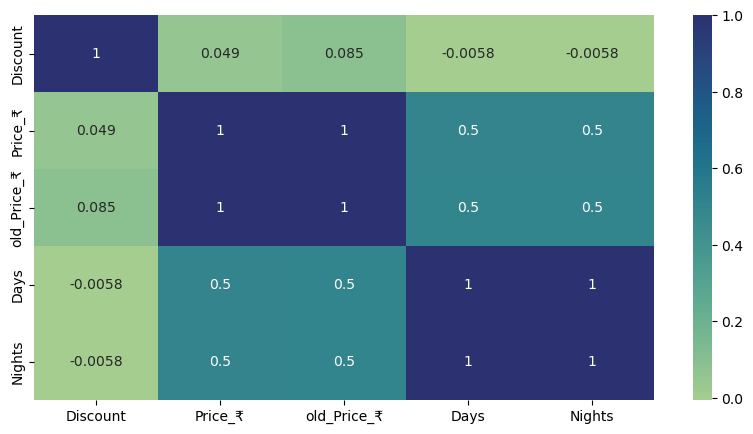

In [30]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="crest")

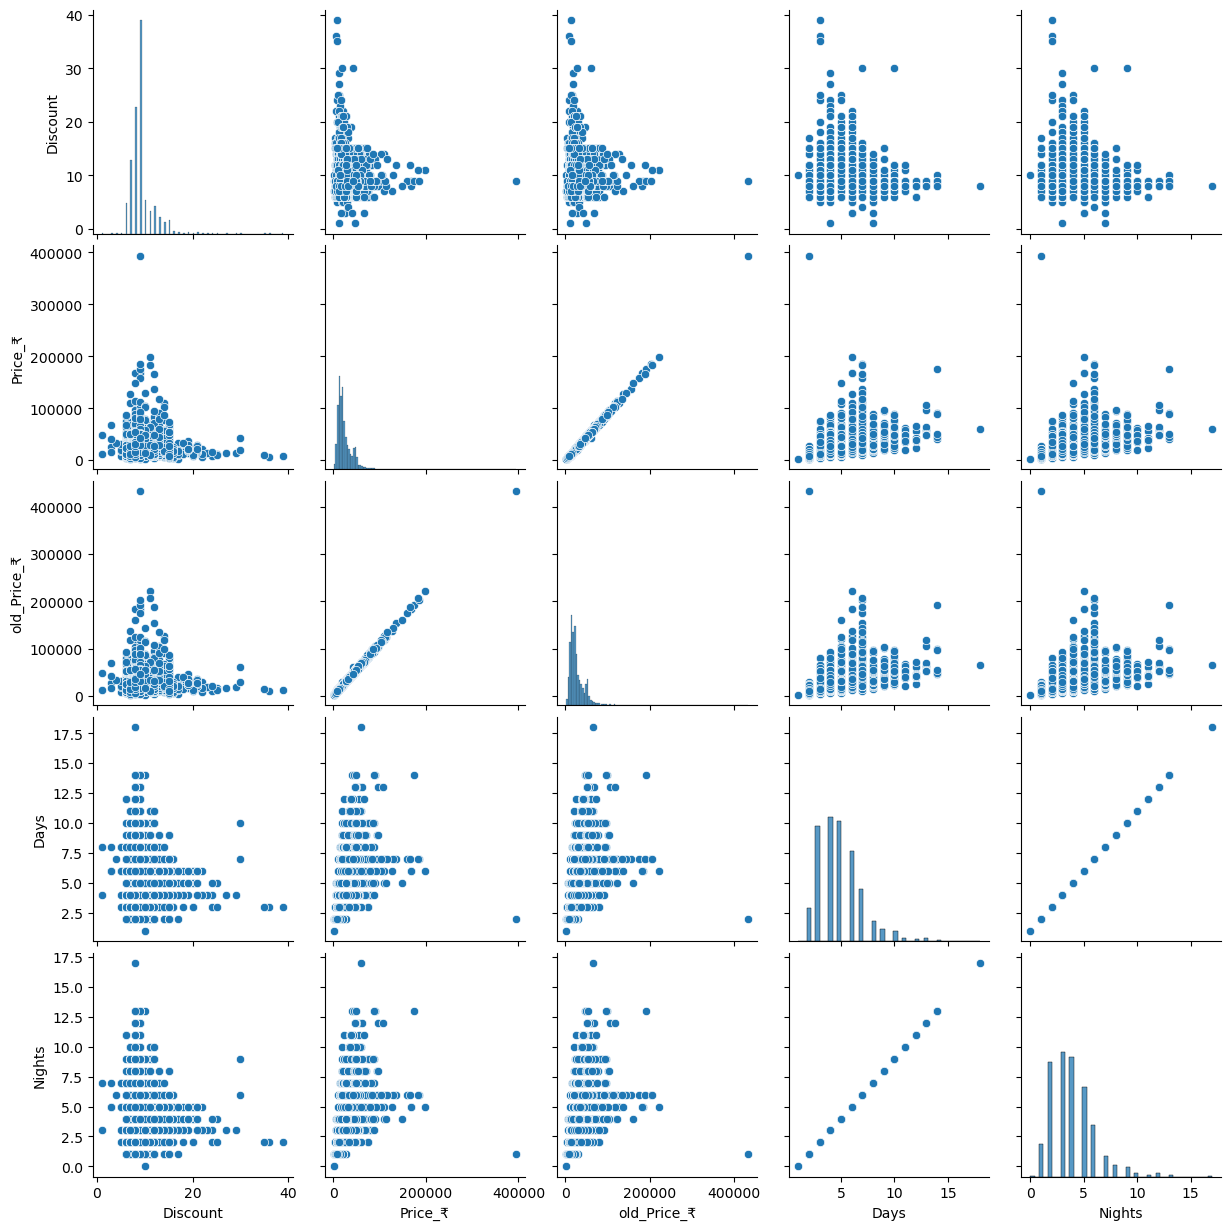

In [31]:
sns.pairplot(df)

<head>
<title></title>
</head>
<body>
    <h1>Univariate Analysis</h1>
</body>

In [32]:
df["Discount"].describe()

count    3232.000000
mean        9.210396
std         2.601391
min         1.000000
25%         8.000000
50%         9.000000
75%         9.000000
max        39.000000
Name: Discount, dtype: float64

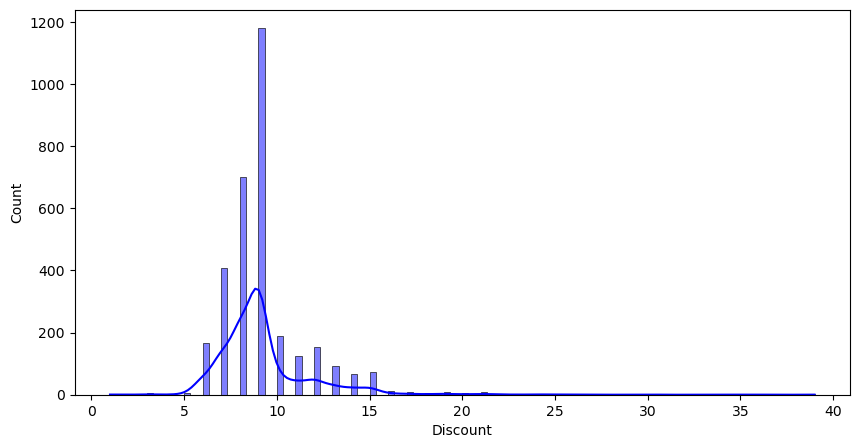

In [33]:
sns.histplot(data=df, x="Discount",kde=True,color="blue")
plt.show()

In [34]:
df["Discount"].skew()

np.float64(3.0898410761027204)

# Obervation
### Most data points are concentrated between 5 and 12 tallest bars here.
### Very few values exist beyond 15–20 small bars.
### The distribution looks right-skewed (positively skewed):
### A long tail extends toward higher values (20–40).

In [35]:
df["Price_₹"].describe()

count          3232.0
mean     25079.214418
std      18925.089444
min            1500.0
25%           13799.0
50%           20000.0
75%           30558.0
max          393750.0
Name: Price_₹, dtype: Float64

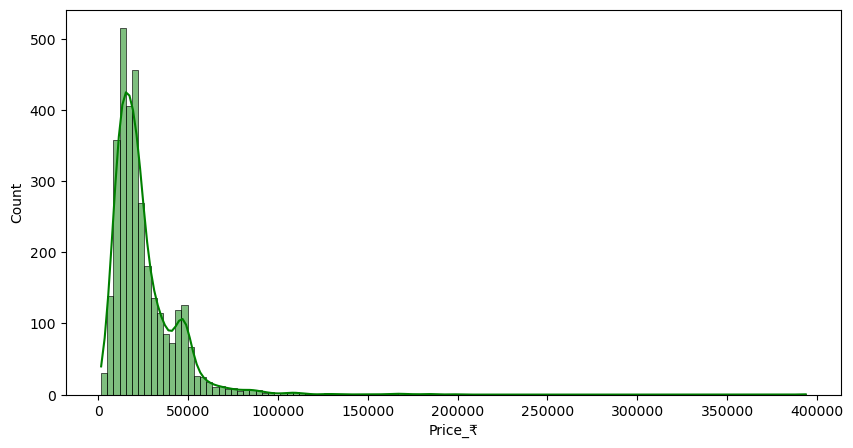

In [36]:
sns.histplot(data=df, x="Price_₹",kde=True,color="green")
plt.show()

In [37]:
df["Price_₹"].skew()

np.float64(4.717620480670055)

# Observation
Most prices are concentrated between ₹10,000 and ₹40,000
tallest bars are here.
Very few items have very high prices (₹100,000+)
small bars on the right side.
There is a long tail extending to the right
indicates right-skewed (positively skewed) distribution.

Majority of products are low to mid-priced.
A few expensive outliers exist (up to ₹400,000).
Mean (average) price will be higher than median due to skewness.

In [38]:
df["old_Price_₹"].describe()

count          3232.0
mean     27674.435953
std      20968.308277
min            1667.0
25%           15099.5
50%           22270.0
75%          34094.25
max          432692.0
Name: old_Price_₹, dtype: Float64

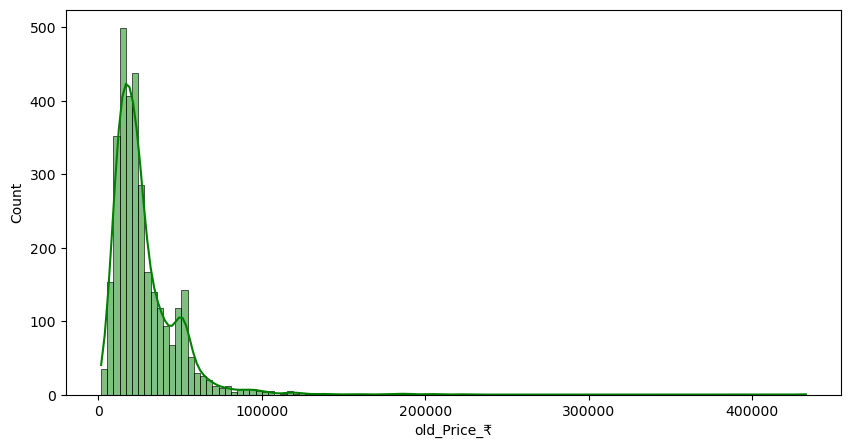

In [39]:
sns.histplot(data=df, x="old_Price_₹",kde=True,color="green")
plt.show()

In [40]:
df["old_Price_₹"].skew()

np.float64(4.682072324015632)

# Observation
Most products have old prices between ₹10,000 and ₹40,000
highest bars in this region.
Very few products have extremely high old prices (₹100,000+)
very small bars on the right.
The graph has a long right tail
indicates a right-skewed (positively skewed) distribution.

Majority of products were originally priced in the lower-mid range. A few very expensive products (outliers) push the range up to ₹400k+. The mean old price is higher than the median due to skewness.

In [41]:
df["Days"].describe()

count    3232.000000
mean        4.945545
std         1.996470
min         1.000000
25%         3.000000
50%         5.000000
75%         6.000000
max        18.000000
Name: Days, dtype: float64

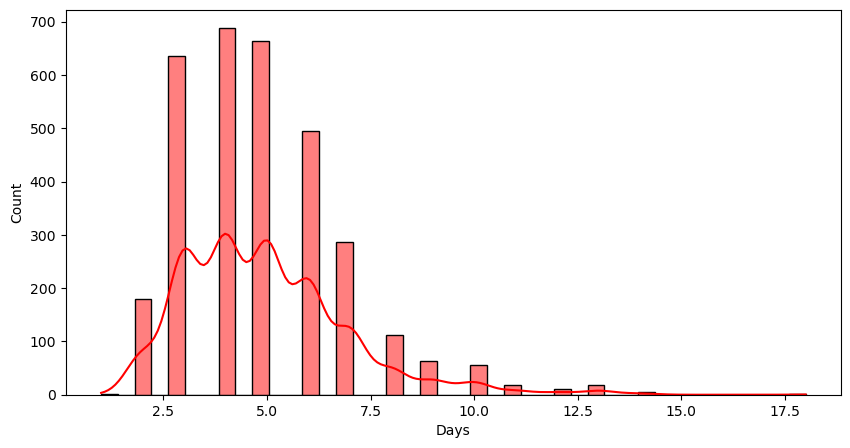

In [42]:
sns.histplot(data=df, x="Days",kde=True,color="red")
plt.show()

In [43]:
df["Days"].skew()

np.float64(1.2287938950193202)

# Observation
Most Packages have Days between 2 and 7
highest bars in this region.
Very few packages have extremely high Days
very small bars on the right.
The graph has a long right tail
indicates a right-skewed (positively skewed) distribution.

Majority of packages were originally priced in the lower-mid range.
A few very expensive products (outliers) push the range up to 17 days.
The mean Days is lower than the median due to skewness.

In [44]:
df["Nights"].describe()

count    3232.000000
mean        3.945545
std         1.996470
min         0.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        17.000000
Name: Nights, dtype: float64

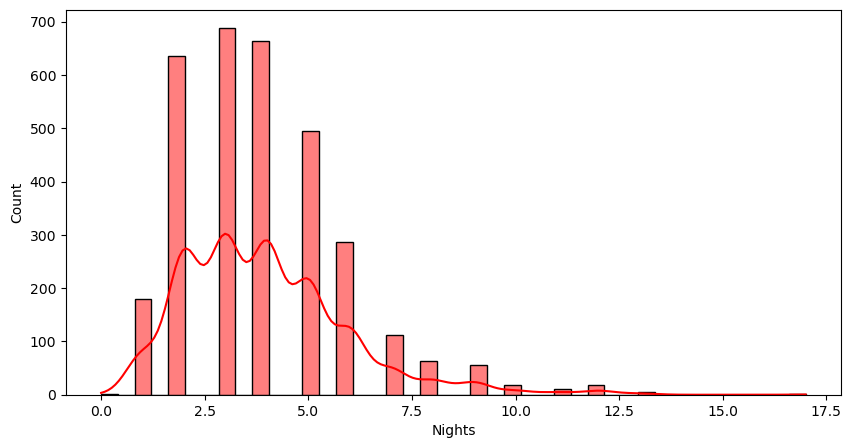

In [45]:
sns.histplot(data=df, x="Nights",kde=True,color="red")
plt.show()

In [46]:
df["Nights"].skew()

np.float64(1.2287938950193213)

# Observation
The distribution is right-skewed, with most values between 2–5.
Peak occurs around 3, indicating the most common night values.
Few high values (above 8–10) suggest rare outliers or spikes

In [47]:
df["Title"].value_counts()

Title
5-Day Kerala Tour with Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare               6
5-Day Kerala Tour: Munnar, Thekkady & AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                      6
4-Day Kerala Tour with Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                          5
5-Day Kerala Tour: Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                   4
4-Day Kerala Tour: Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                              3
                                                                                                                                        ..
Amusing Karnataka TourPlease deselect at least one item. Only 3 are allowed. Add To Compare                                              1
Best Selling Getaways

In [48]:
df["Title"].value_counts(normalize=True) * 100

Title
5-Day Kerala Tour with Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare               0.185644
5-Day Kerala Tour: Munnar, Thekkady & AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                      0.185644
4-Day Kerala Tour with Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                          0.154703
5-Day Kerala Tour: Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                   0.123762
4-Day Kerala Tour: Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                              0.092822
                                                                                                                                           ...   
Amusing Karnataka TourPlease deselect at least one item. Only 3 are allowed. Add To Compare                           

In [49]:
df['Title'].value_counts().head(10)

Title
5-Day Kerala Tour with Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare    6
5-Day Kerala Tour: Munnar, Thekkady & AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare           6
4-Day Kerala Tour with Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare               5
5-Day Kerala Tour: Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare        4
4-Day Kerala Tour: Munnar and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare                   3
6-Day Kerala Tour with Munnar, Thekkady, and AlleppeyPlease deselect at least one item. Only 3 are allowed. Add To Compare    3
3-Day Kerala Tour: Munnar's Tea Gardens & WaterfallsPlease deselect at least one item. Only 3 are allowed. Add To Compare     3
4-Day Kerala Tour with Munnar and Alleppey HouseboatPlease deselect at least one item. Only 3 are 

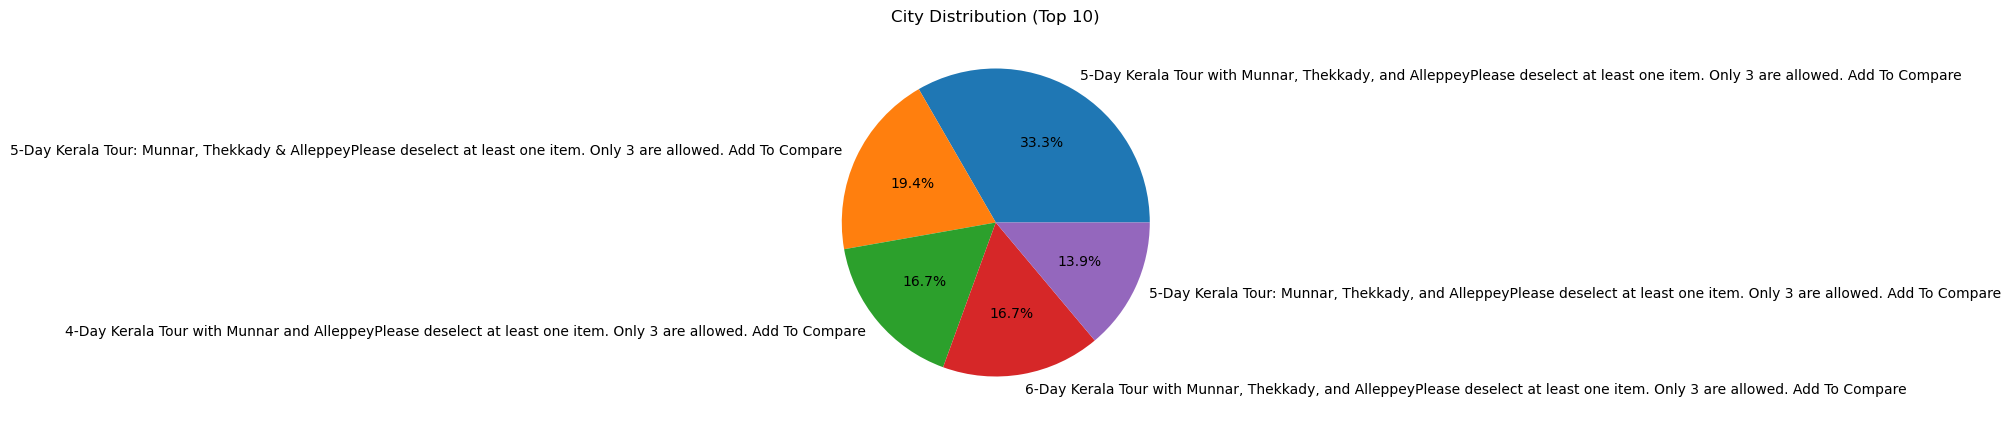

In [142]:
df['Title'].value_counts().head(5).plot.pie(autopct='%1.1f%%')
plt.title("City Distribution (Top 10)")
plt.ylabel("")
plt.show()

# Observation:
1.Top 10 titles are distributed their percentage that they was frequently occured

In [51]:
df["Hotels"].value_counts()

Hotels
3 Star    2109
4 Star     667
2 Star     371
5 Star      85
Name: count, dtype: int64

In [52]:
df["Hotels"].value_counts(normalize=True) * 100

Hotels
3 Star    65.253713
4 Star    20.637376
2 Star    11.478960
5 Star     2.629950
Name: proportion, dtype: float64

In [53]:
df['Hotels'].value_counts()

Hotels
3 Star    2109
4 Star     667
2 Star     371
5 Star      85
Name: count, dtype: int64

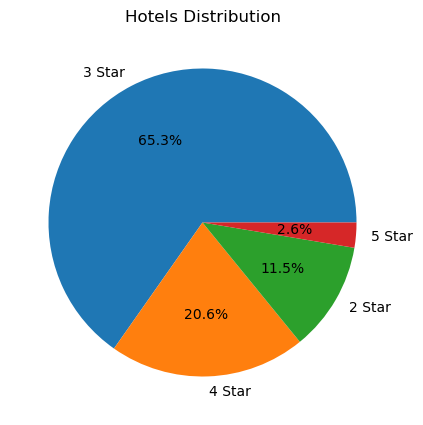

In [54]:
df['Hotels'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Hotels Distribution")
plt.ylabel("")
plt.show()

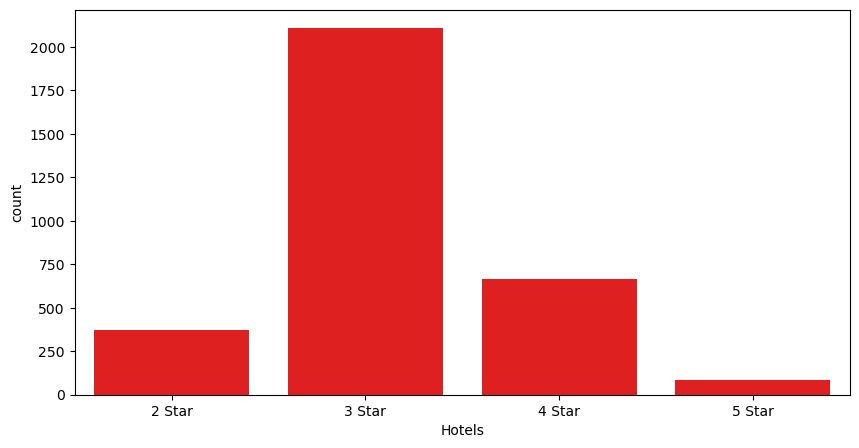

In [55]:
sns.countplot(x=df["Hotels"],color="red")
plt.show()

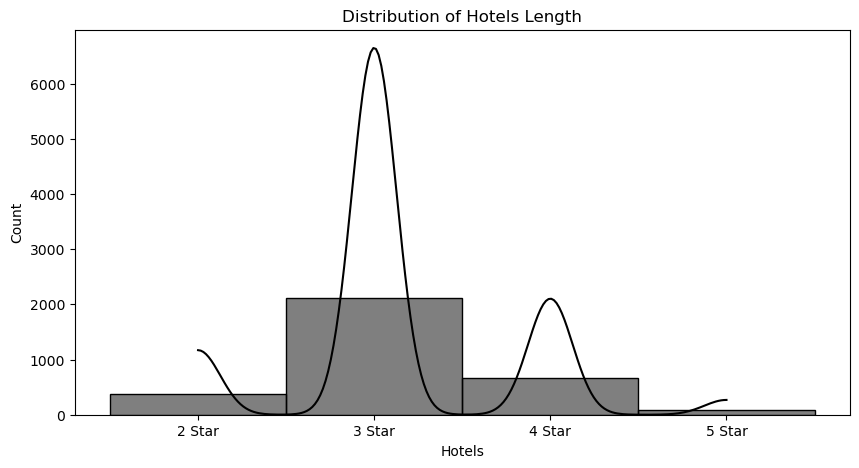

In [56]:
sns.histplot(df['Hotels'], bins=30, kde=True,color="black")
plt.title("Distribution of Hotels Length")
plt.show()

### 3-star hotels dominate the dataset, showing most listings are in the mid-range segment.
### 4-star hotels are the second most common, indicating demand for slightly premium stays.
### 2-star hotels are very few, suggesting low availability or demand for budget options.
### 5-star hotels are rare, showing limited luxury offerings.
Overall, the data is centered around mid-range hotels (3–4 star) with very low representation at both budget and luxury extremes.

In [57]:
df["Package_sharing"].value_counts()

Package_sharing
Per Person on twin sharing    3224
Total                            8
Name: count, dtype: int64

In [58]:
df["Package_sharing"].value_counts(normalize=True) * 100

Package_sharing
Per Person on twin sharing    99.752475
Total                          0.247525
Name: proportion, dtype: float64

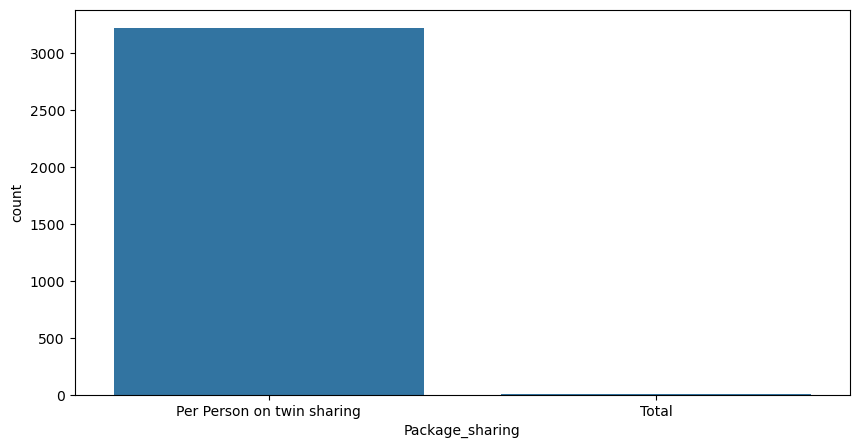

In [59]:
sns.countplot(x=df["Package_sharing"])
plt.show()

# Obervation
1.Per person on win sharing has more preferable than total
2.mostly people take this offer 

In [60]:
df["Cities"].value_counts()

Cities
Munnar         591
Shimla         155
Goa            121
Srinagar       114
Manali         106
              ... 
Nahan            1
Balasore         1
Tuljapur         1
Sawantwadi       1
Coimbatore       1
Name: count, Length: 242, dtype: int64

In [61]:
df["Cities"].value_counts(normalize=True) * 100

Cities
Munnar         18.285891
Shimla          4.795792
Goa             3.743812
Srinagar        3.527228
Manali          3.279703
                 ...    
Nahan           0.030941
Balasore        0.030941
Tuljapur        0.030941
Sawantwadi      0.030941
Coimbatore      0.030941
Name: proportion, Length: 242, dtype: float64

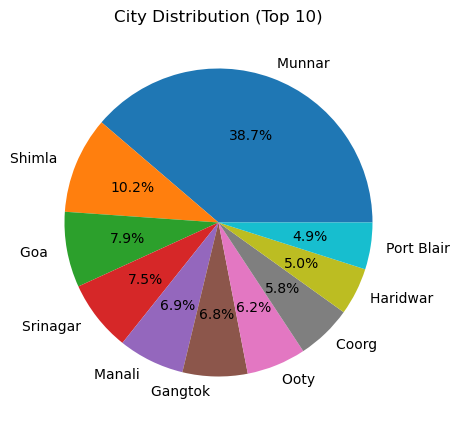

In [62]:
df['Cities'].value_counts().head(10).plot.pie(autopct='%1.1f%%')
plt.title("City Distribution (Top 10)")
plt.ylabel("")
plt.show()

# Observation
1.Top 10 cities that have mostly occured in paackages
2.1 is Munnar ahe 10 is Port Blair
3.we understand using Pie chart in our data most Packages on Munnar City

In [63]:
df['Cities'].value_counts().head(10)

Cities
Munnar         591
Shimla         155
Goa            121
Srinagar       114
Manali         106
Gangtok        104
Ooty            95
Coorg           89
Haridwar        76
Port Blair      75
Name: count, dtype: int64

<head>
<title></title>
</head>
<body>
    <h1>Bivariate Analysis</h1>
</body>

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3232 entries, 0 to 3919
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            3232 non-null   object 
 1   Discount         3232 non-null   float64
 2   Hotels           3232 non-null   object 
 3   Package_sharing  3232 non-null   object 
 4   Price_₹          3232 non-null   Int64  
 5   old_Price_₹      3232 non-null   Int64  
 6   Days             3232 non-null   int64  
 7   Nights           3232 non-null   int64  
 8   Cities           3232 non-null   object 
dtypes: Int64(2), float64(1), int64(2), object(4)
memory usage: 258.8+ KB


<Axes: >

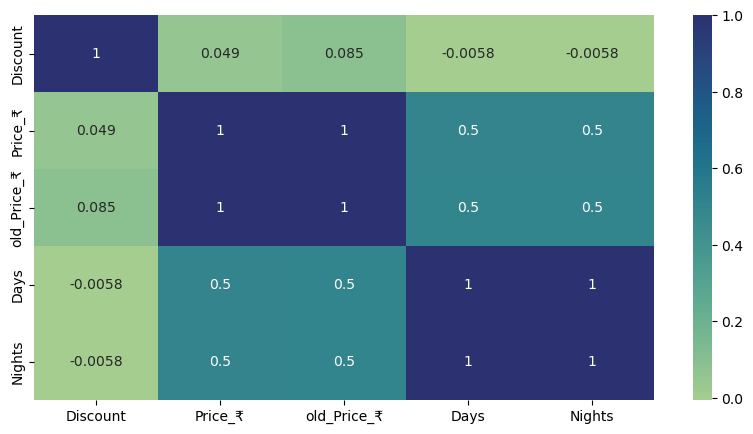

In [65]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="crest")

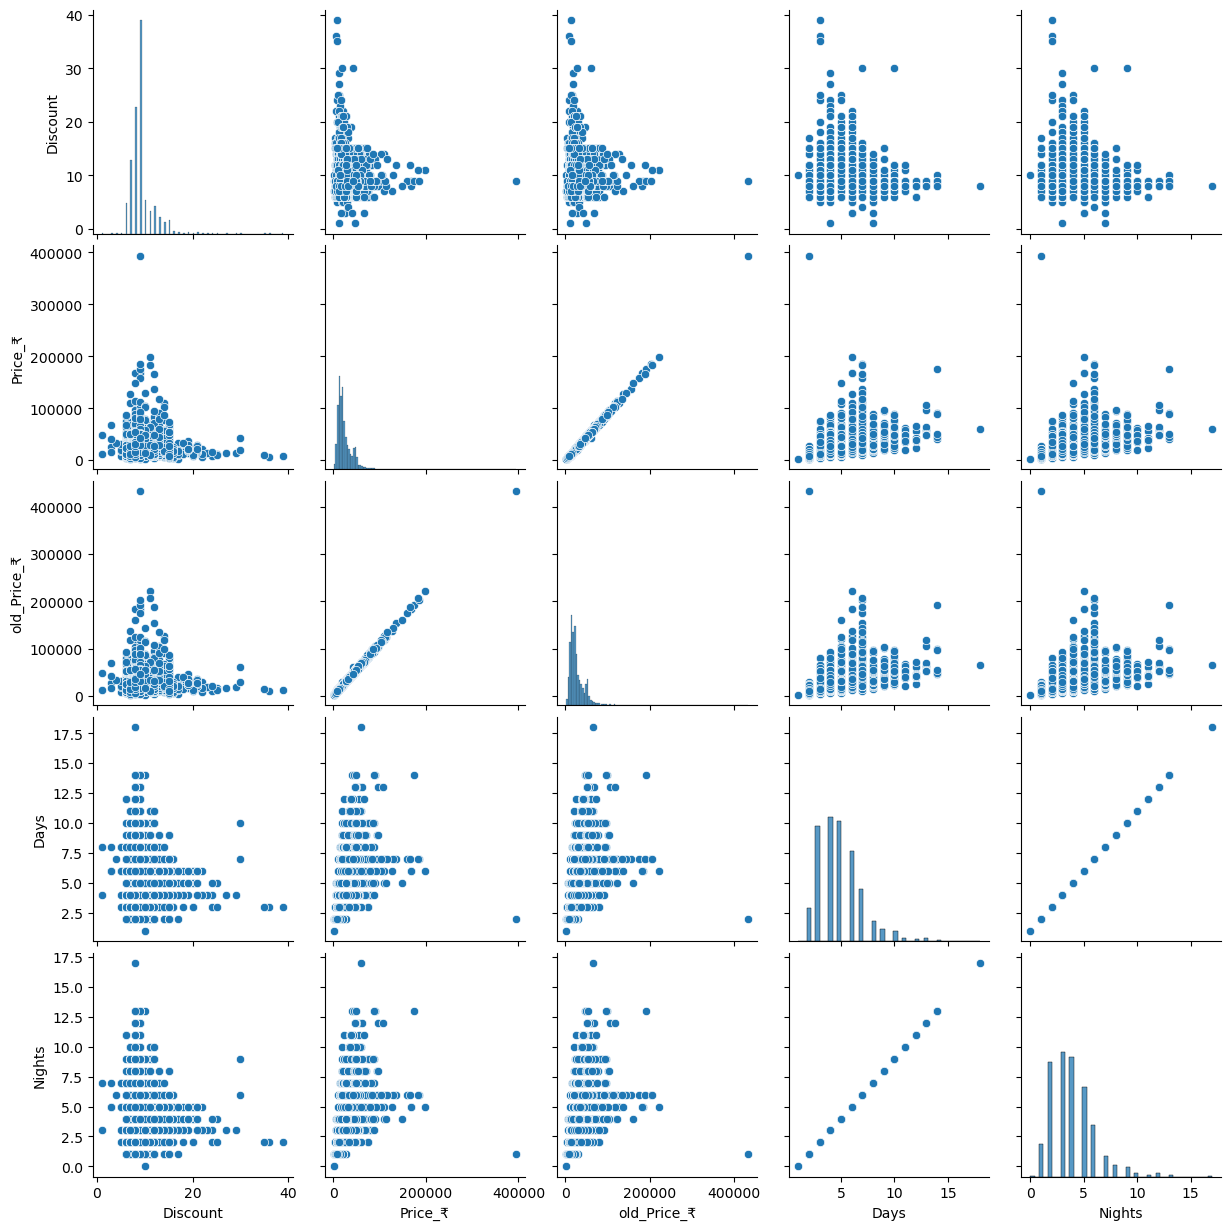

In [66]:
sns.pairplot(df)

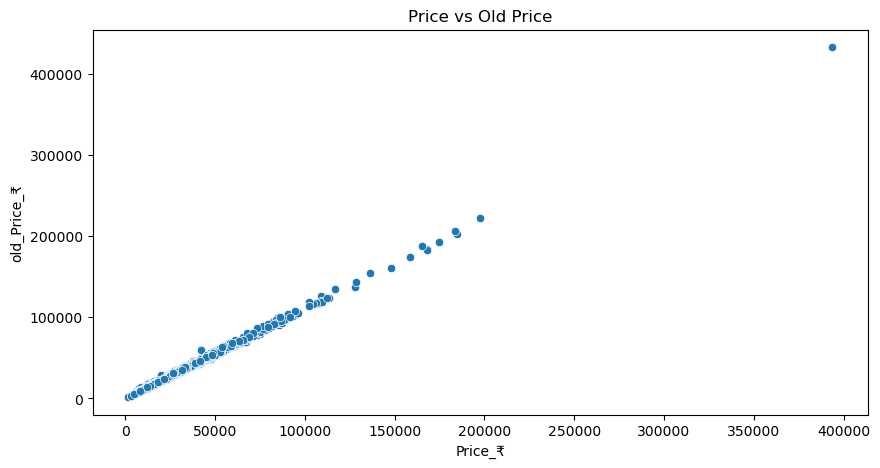

In [67]:
sns.scatterplot(x=df['Price_₹'], y=df['old_Price_₹'])
plt.title("Price vs Old Price")
plt.show()

# Observation
1.There is a strong positive linear relationship between current price and old price.
2.As the current price increases, the old price also increases proportionally.
3.Most points lie close to a straight line, indicating consistent discount patterns.
4.A few high-value points suggest premium packages with higher original prices

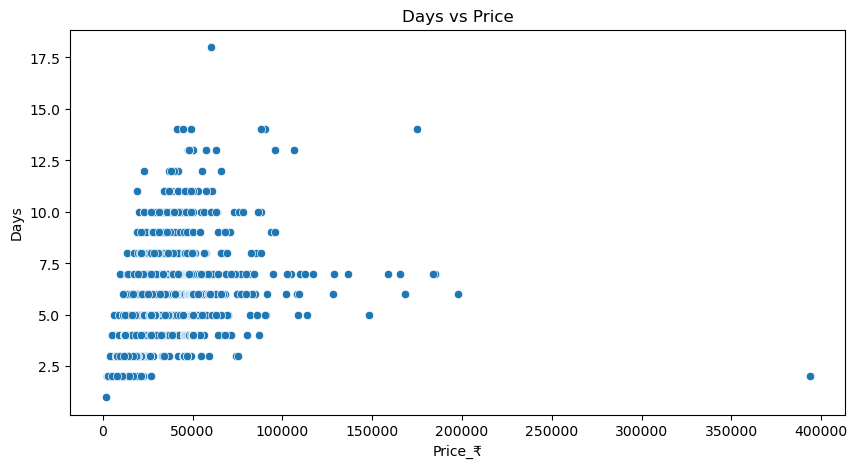

In [90]:
sns.scatterplot(x=df["Price_₹"], y=df['Days'])
plt.title("Days vs Price")
plt.show()

# Observation
1.There is a slight positive relationship between days and price, but it is not very strong.
2.Most data is clustered between 3–10 days with mid-range prices.
3.Prices vary a lot even for the same number of days, indicating other influencing factors.
4.A few extreme outliers (~400k) suggest premium listings or anomalies.

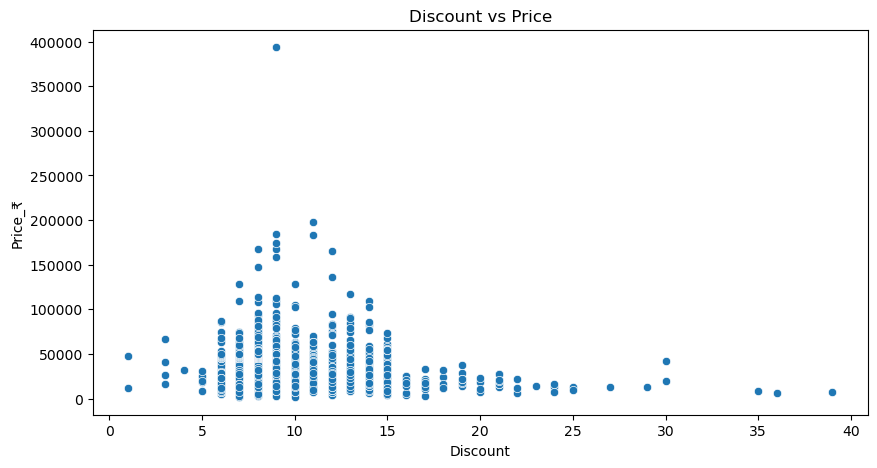

In [89]:
sns.scatterplot(x=df['Discount'], y=df['Price_₹'])
plt.title("Discount vs Price")
plt.show()

# Observation
1.There is an inverse relationship—as discount increases, price generally decreases.
2.Most bookings fall within the 5–15% discount range.
3.High-priced listings usually have lower discounts.
4.Very high discounts (>25%) are mostly applied to low-priced listings.

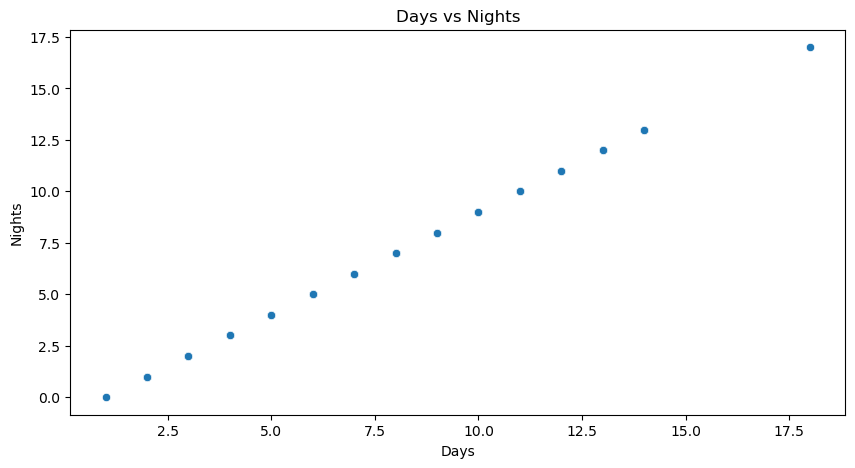

In [68]:
sns.scatterplot(x=df['Days'], y=df['Nights'])
plt.title("Days vs Nights")
plt.show()

# Observation
1.There is a strong positive linear relationship between Days and Nights.
2.As the number of days increases, nights increase proportionally.
3.The data follows a consistent pattern (approximately Nights = Days − 1).
4.No outliers are present, indicating clean and reliable data.

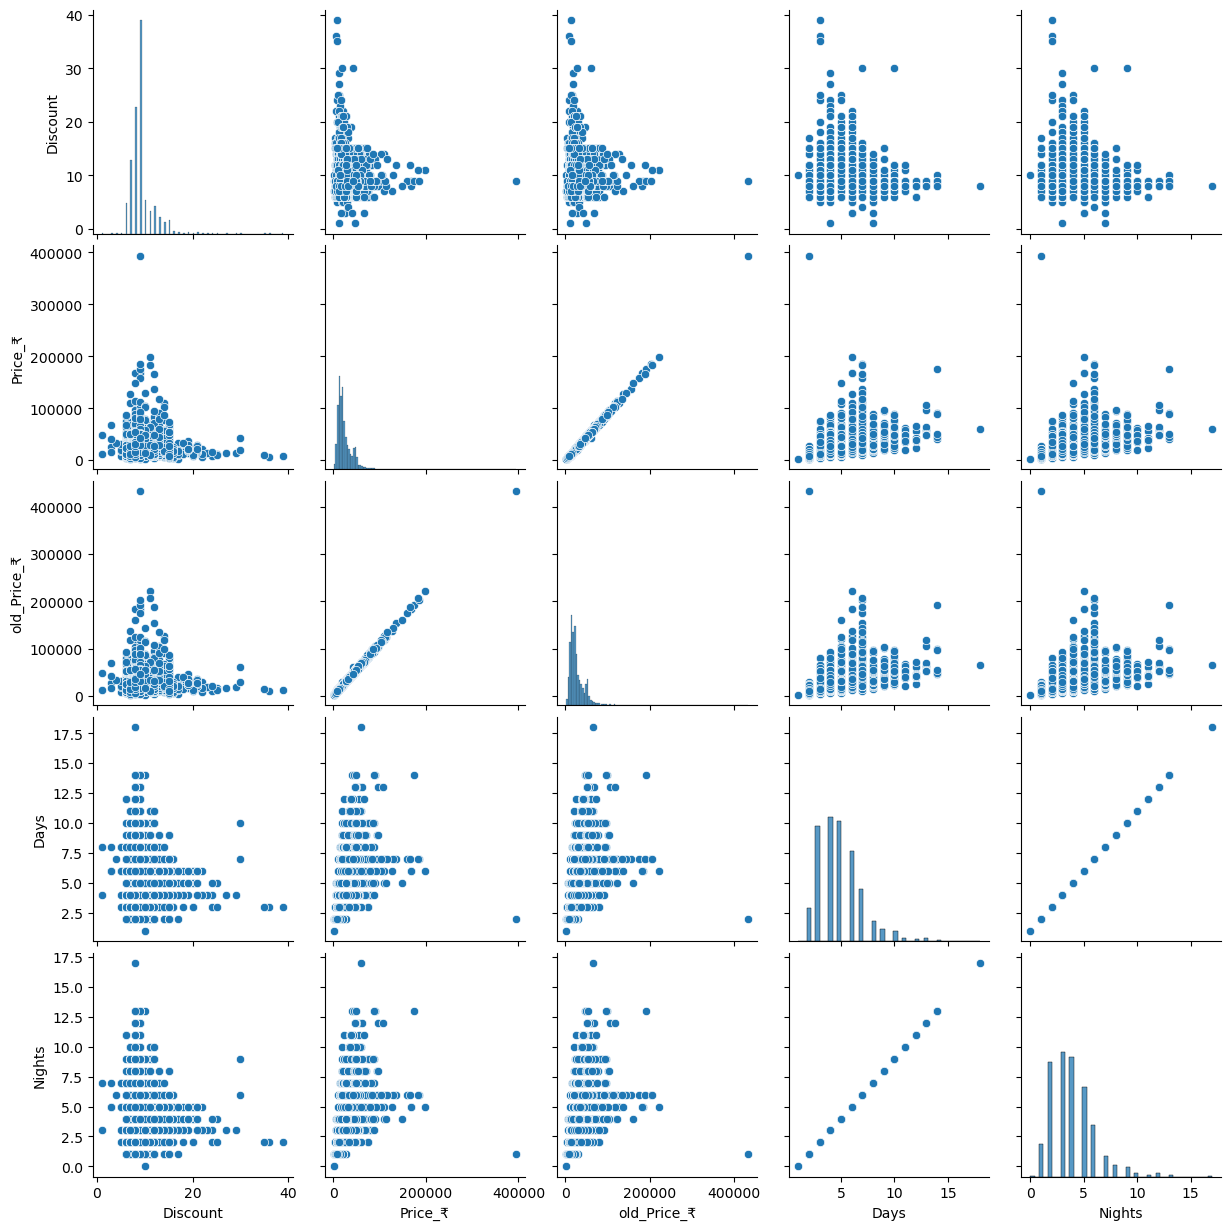

In [69]:
sns.pairplot(df[['Discount','Price_₹','old_Price_₹','Days','Nights']])
plt.show()

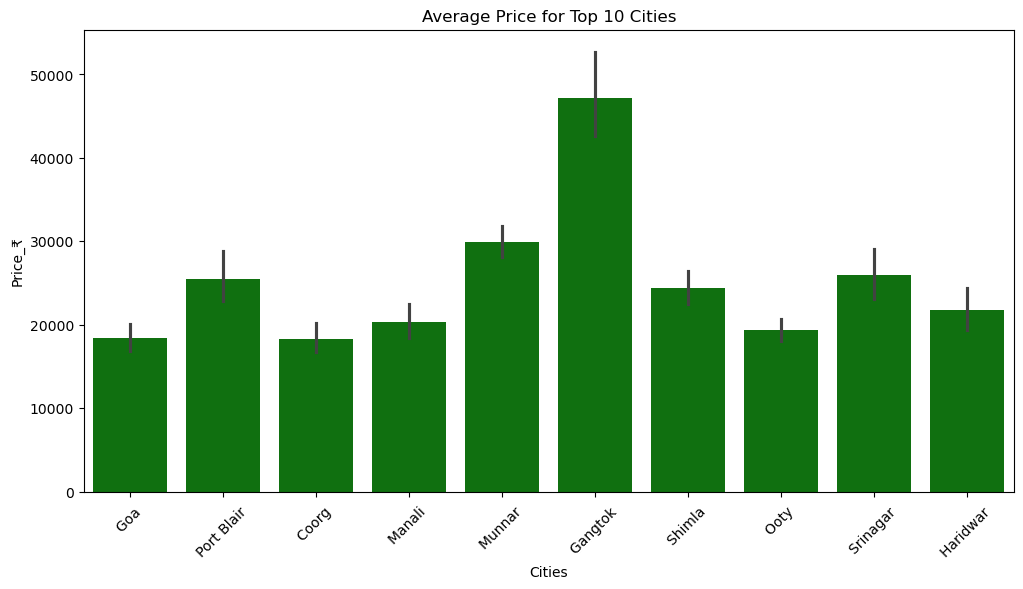

In [70]:
top10 = df['Cities'].value_counts().head(10).index
df_top10 = df[df['Cities'].isin(top10)]
plt.figure(figsize=(12,6))
sns.barplot(x='Cities', y='Price_₹', data=df_top10,color="green")
plt.xticks(rotation=45)
plt.title("Average Price for Top 10 Cities")
plt.show()

# Observation
1.Gangtok has the highest average price, making it the most expensive destination among the top 10.
2.Munnar and Srinagar also show relatively higher pricing compared to others.
3.Goa, Coorg, and Ooty are more budget-friendly options.
4.Moderate price variation across cities suggests diverse pricing based on popularity, location, and travel demand.

In [72]:
df.corr(numeric_only=True).unstack().sort_values(ascending=False)

Nights       Days           1.000000
Days         Nights         1.000000
Discount     Discount       1.000000
Price_₹      Price_₹        1.000000
Days         Days           1.000000
old_Price_₹  old_Price_₹    1.000000
Nights       Nights         1.000000
old_Price_₹  Price_₹        0.999037
Price_₹      old_Price_₹    0.999037
Nights       Price_₹        0.501808
Price_₹      Nights         0.501808
             Days           0.501808
Days         Price_₹        0.501808
old_Price_₹  Nights         0.497931
Nights       old_Price_₹    0.497931
old_Price_₹  Days           0.497931
Days         old_Price_₹    0.497931
old_Price_₹  Discount       0.085336
Discount     old_Price_₹    0.085336
Price_₹      Discount       0.049340
Discount     Price_₹        0.049340
             Days          -0.005838
Days         Discount      -0.005838
Nights       Discount      -0.005838
Discount     Nights        -0.005838
dtype: float64

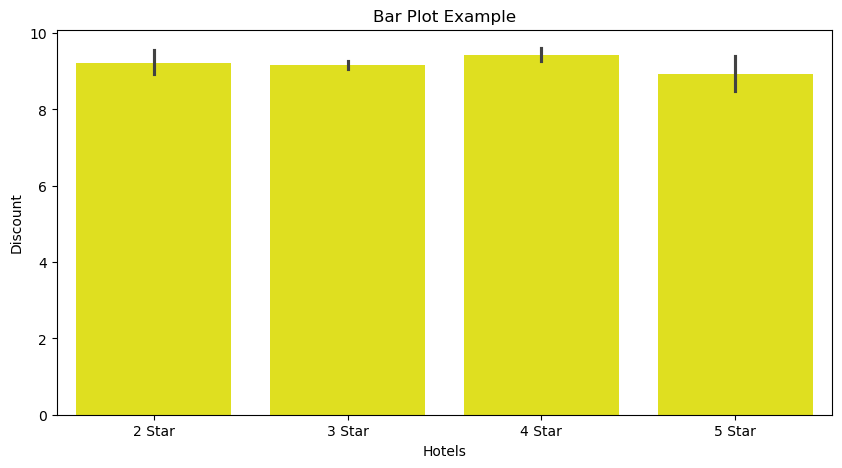

In [94]:
sns.barplot(x='Hotels', y='Discount', data=df,color="Yellow")
plt.title("Bar Plot Example")
plt.show()

# Observation
1.4-star hotels offer the highest average discount, making them the best value-for-money option.
2.Discounts across all hotel categories are quite similar, showing minimal variation.
3.5-star hotels have slightly lower discounts, likely due to premium pricing.
4.Overall, discounts are consistent, indicating stable pricing strategies across hotel types

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3232 entries, 0 to 3919
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            3232 non-null   object 
 1   Discount         3232 non-null   float64
 2   Hotels           3232 non-null   object 
 3   Package_sharing  3232 non-null   object 
 4   Price_₹          3232 non-null   Int64  
 5   old_Price_₹      3232 non-null   Int64  
 6   Days             3232 non-null   int64  
 7   Nights           3232 non-null   int64  
 8   Cities           3232 non-null   object 
dtypes: Int64(2), float64(1), int64(2), object(4)
memory usage: 258.8+ KB


In [75]:
df["Discount"].value_counts().index

Index([ 9.0,  8.0,  7.0, 10.0,  6.0, 12.0, 11.0, 13.0, 15.0, 14.0, 16.0, 19.0,
       17.0, 21.0,  5.0, 18.0, 20.0,  3.0, 24.0, 22.0, 25.0,  1.0, 30.0, 29.0,
       39.0, 23.0, 36.0,  4.0, 27.0, 35.0],
      dtype='float64', name='Discount')

In [76]:
df.loc[df["Discount"].idxmax()]

Title              Exclusive Kerala Munnar Tour Packages for an A...
Discount                                                        39.0
Hotels                                                        3 Star
Package_sharing                           Per Person on twin sharing
Price_₹                                                         7840
old_Price_₹                                                    12792
Days                                                               3
Nights                                                             2
Cities                                                       Munnar 
Name: 141, dtype: object

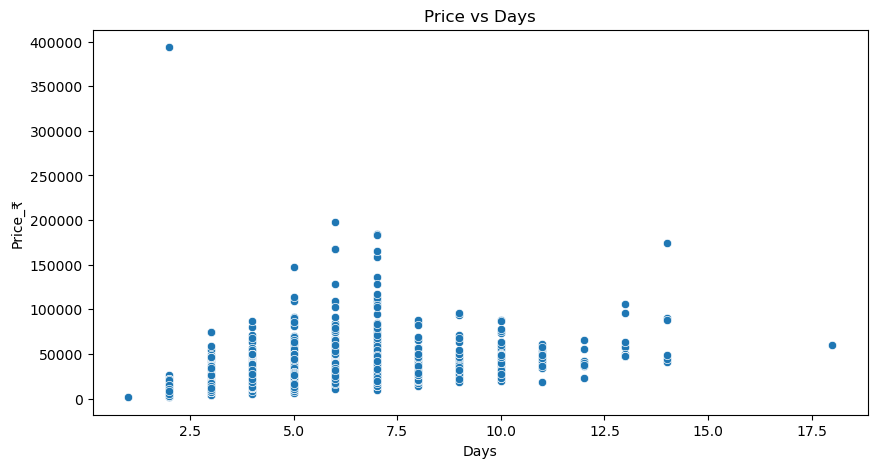

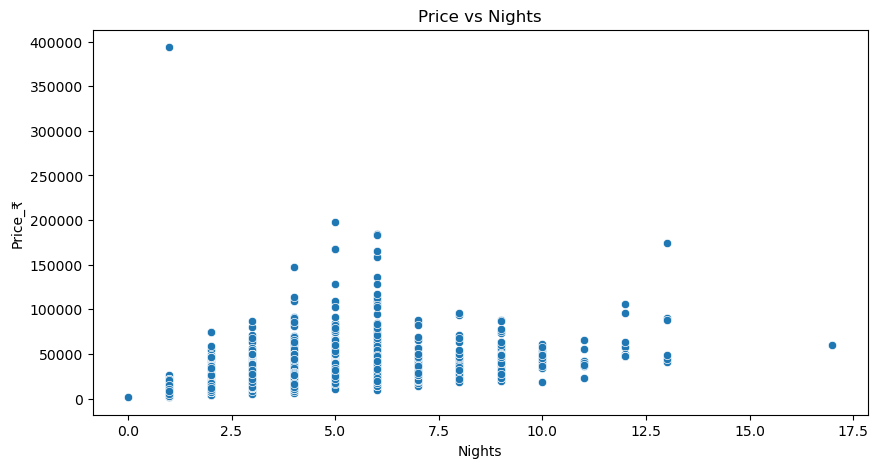

In [93]:
sns.scatterplot(x=df['Days'], y=df['Price_₹'])
plt.title("Price vs Days")
plt.show()

sns.scatterplot(x=df['Nights'], y=df['Price_₹'])
plt.title("Price vs Nights")
plt.show()

# Observation
1.Price generally increases as the number of days/nights increases, showing a positive trend.
2.Most bookings are concentrated between 4–8 days/nights with moderate pricing.
3.There are a few extreme high-price outliers (around 400k), indicating premium or luxury cases.
4.Variability in price is high even for similar durations, suggesting other factors also affect pricing.

In [106]:
pd.pivot_table(df, values='Price_₹', index='Cities', columns='Hotels', aggfunc='mean')

Hotels,2 Star,3 Star,4 Star,5 Star
Cities,,,,
Abu Dhabi,<NA>,22999.0,<NA>,<NA>
Agatti,25559.4,<NA>,<NA>,<NA>
Agra,<NA>,16035.214286,21499.25,<NA>
Ahmedabad,<NA>,24949.0,40000.0,<NA>
Allahabad,<NA>,34000.0,<NA>,51000.0
...,...,...,...,...
Zuluk,<NA>,19000.0,<NA>,<NA>
Zurich,<NA>,45349.0,45349.0,<NA>
kathmandu,<NA>,27699.625,<NA>,<NA>


In [107]:
df.groupby("Cities")['Price_₹'].mean()

Cities
Abu Dhabi          22999.0
Agatti             25559.4
Agra          17249.444444
Ahmedabad     26106.769231
Allahabad          42500.0
                  ...     
Zuluk              19000.0
Zurich             45349.0
kathmandu        27699.625
lavasa             14353.6
sariska             4500.0
Name: Price_₹, Length: 242, dtype: Float64

In [118]:
df.groupby("Cities")['old_Price_₹'].mean()

Cities
Abu Dhabi          25274.0
Agatti             27539.4
Agra          19053.333333
Ahmedabad     28358.230769
Allahabad          48977.5
                  ...     
Zuluk              20652.0
Zurich             49834.0
kathmandu        30342.875
lavasa             15730.2
sariska             5354.0
Name: old_Price_₹, Length: 242, dtype: Float64

In [108]:
df.groupby('Days')[['Price_₹','Nights']].mean()

,Price_₹,Nights
Days,,
1,1500.0,0.0
2,11394.283333,1.0
3,14181.527559,2.0
4,19968.986919,3.0
5,25722.263952,4.0
6,32129.305051,5.0
7,39668.157343,6.0
8,36753.258929,7.0
9,40054.650794,8.0


In [109]:
df.groupby('Discount')['Price_₹'].mean()

Discount
1.0          29796.0
3.0          37499.5
4.0          31999.0
5.0     21150.833333
6.0     22470.670659
7.0     21330.391198
8.0     26425.562857
9.0     23858.994068
10.0    26271.765957
11.0    29030.357143
12.0    27401.006452
13.0    35369.384615
14.0    34432.833333
15.0    28853.589041
16.0    17779.307692
17.0    16431.555556
18.0         19275.4
19.0    22087.666667
20.0        14674.75
21.0       20249.125
22.0    13327.666667
23.0         13909.0
24.0    12173.333333
25.0         11000.0
27.0         12595.0
29.0         13167.0
30.0         30998.5
35.0          8838.0
36.0          6000.0
39.0          7840.0
Name: Price_₹, dtype: Float64

# Observation
1.Price and old price are almost perfectly correlated grouping either gives same trend
2.Days and Nights have strong relation useful for grouped averages
3.Discount has very weak correlation little impact on price
4.Grouping by Days gives meaningful pricing patterns

In [110]:
pd.pivot_table(df, values='Price_₹', index='Days', columns='Nights', aggfunc='mean')

Nights,0,1,2,3,4,5,6,7,8,9,10,11,12,13,17
Days,,,,,,,,,,,,,,,
1,1500.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,<NA>,11394.283333,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,<NA>,<NA>,14181.527559,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,<NA>,<NA>,<NA>,19968.986919,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5,<NA>,<NA>,<NA>,<NA>,25722.263952,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
6,<NA>,<NA>,<NA>,<NA>,<NA>,32129.305051,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
7,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,39668.157343,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
8,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,36753.258929,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
9,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,40054.650794,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [111]:
pd.pivot_table(df, values='Price_₹', index='Discount', columns='Days', aggfunc='mean')

Days,1,2,3,4,5,6,7,8,9,10,11,12,13,14,18
Discount,,,,,,,,,,,,,,,
1.0,<NA>,<NA>,<NA>,12092.0,<NA>,<NA>,<NA>,47500.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3.0,<NA>,<NA>,<NA>,<NA>,<NA>,36333.0,<NA>,40999.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,31999.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5.0,<NA>,<NA>,8500.0,20154.0,<NA>,20976.5,<NA>,28149.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
6.0,<NA>,10072.037037,14593.117647,21722.275862,24225.352941,31637.444444,27008.1,47836.0,63921.0,32500.0,<NA>,38849.0,<NA>,<NA>,<NA>
7.0,<NA>,10070.848485,13731.613208,17351.373913,22946.769231,33870.630435,34217.375,37189.176471,36065.2,53083.75,43707.666667,<NA>,<NA>,<NA>,<NA>
8.0,<NA>,10468.551724,14220.701923,21708.837398,25272.930818,30047.356522,33666.013699,35799.296296,43893.52381,41837.454545,44395.666667,41978.5,49049.25,68800.0,60500.0
9.0,<NA>,13535.909091,14036.952381,19319.597701,24198.353191,29608.33908,38928.705263,35051.861111,36475.142857,49807.875,41652.5,44489.0,69196.666667,103218.333333,<NA>
10.0,1500.0,8739.375,14259.787879,19267.439024,25016.432432,33971.852941,51582.0,27198.0,39500.0,46724.5,<NA>,<NA>,<NA>,41151.0,<NA>


# Obervation
1.Days vs Nights shows strong structured relationship (correlation = 1)
2.Price increases consistently with Days/Nights combinations
3.Discount-based pivot shows minimal variation in price
4.Best analysis comes from Days & Nights combination

In [113]:
pd.crosstab(df['Days'], df['Nights'])

Nights,0,1,2,3,4,5,6,7,8,9,10,11,12,13,17
Days,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,180,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,635,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,688,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,663,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,495,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,286,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,112,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,63,0,0,0,0,0,0


In [114]:
pd.crosstab(df['Discount'], df['Days'])

Days,1,2,3,4,5,6,7,8,9,10,11,12,13,14,18
Discount,,,,,,,,,,,,,,,
1.0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
3.0,0,0,0,0,0,3,0,1,0,0,0,0,0,0,0
4.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
5.0,0,0,1,1,0,2,0,2,0,0,0,0,0,0,0
6.0,0,27,34,29,34,18,10,10,1,1,0,3,0,0,0
7.0,0,33,106,115,52,46,24,17,5,8,3,0,0,0,0
8.0,0,29,104,123,159,115,73,27,21,22,6,6,12,2,1
9.0,0,66,252,261,235,174,95,36,28,16,6,2,6,3,0
10.0,1,8,33,41,37,34,22,8,1,2,0,0,0,1,0


# Observation
1.Days and Nights combinations occur very consistently (strong relationship)
2.Crosstab confirms 1:1 pattern between Days & Nights
3.Discount distribution is uniform across days
4.Frequency analysis is most useful for Days vs Nights

In [117]:
pd.crosstab(df['Cities'], df['Hotels']).head()

Hotels,2 Star,3 Star,4 Star,5 Star
Cities,,,,
Abu Dhabi,0,1,0,0
Agatti,5,0,0,0
Agra,0,14,4,0
Ahmedabad,0,12,1,0
Allahabad,0,1,0,1
